In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = "/content/drive/MyDrive/hausa_news_project"
os.makedirs(PROJECT_DIR, exist_ok=True)
os.chdir(PROJECT_DIR)

print("Working directory:", os.getcwd())
print("Files:", os.listdir("."))
required = ["train.csv", "val.csv", "test.csv", "labels.json"]
missing = [f for f in required if f not in os.listdir(".")]
print("Missing files:", missing if missing else "none, ready to go")

Mounted at /content/drive
Working directory: /content/drive/MyDrive/hausa_news_project
Files: ['train.csv', 'val.csv', 'test.csv', 'labels.json', 'baseline_C_tuning.csv', 'w2v_matrix.pt', 'ft_matrix.pt', 'ckpt', 'neural_learning_curves.png', 'neural_confusion_matrix.png', 'neural_errors.csv', 'best_neural.pt', 'preds', 'best_transformer', 'space', 'baseline_tuning.csv', 'baseline_confusion_matrix.png', 'baseline_errors.csv', 'neural_seed_runs.csv', 'transformer_confusion_matrix.png', 'transformer_errors.csv', 'model_comparison.png', 'results.json', '.gradio', 'app', 'validation_comparison.png', 'test_comparison.png', 'class_distribution.png', 'length_distribution.png', 'per_class_f1.png', 'confidence_hist.png', 'error_annotation.csv', 'error_types.png', 'hooked_letter_error_rate.png', 'test_scores_final.png', 'confusion_final.png']
Missing files: none, ready to go


In [2]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, make_pipeline, make_union
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, classification_report, confusion_matrix)

SEED = 42
np.random.seed(SEED)

train = pd.read_csv("train.csv")
val   = pd.read_csv("val.csv")
test  = pd.read_csv("test.csv")
meta  = json.load(open("labels.json"))
id2label = {int(k): v for k, v in meta["id2label"].items()}
label_names = [id2label[i] for i in range(len(id2label))]

X_train, y_train = train["text_clean"], train["label_id"]
X_val,   y_val   = val["text_clean"],   val["label_id"]
X_test,  y_test  = test["text_clean"],  test["label_id"]
print(len(train), len(val), len(test), label_names)


RESULTS_FILE = "results.json"
try:
    RESULTS = json.load(open(RESULTS_FILE))
except FileNotFoundError:
    RESULTS = []

def compute_metrics(y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred),
            "macro_precision": p, "macro_recall": r, "macro_f1": f1,
            "weighted_f1": f1_score(y_true, y_pred, average="weighted")}

def log_result(name, val_metrics, test_metrics=None, notes=""):
    row = {"model": name, "notes": notes,
           **{f"val_{k}": round(v, 4) for k, v in val_metrics.items()}}
    if test_metrics:
        row.update({f"test_{k}": round(v, 4) for k, v in test_metrics.items()})
    RESULTS[:] = [r for r in RESULTS if r["model"] != name]
    RESULTS.append(row)
    json.dump(RESULTS, open(RESULTS_FILE, "w"), indent=2)

def full_report(name, y_true, y_pred, X_text, prefix="final"):
    print(f"\n===== {name} =====")
    print(classification_report(y_true, y_pred, target_names=label_names, digits=3))
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    plt.figure(figsize=(8, 6.5))
    sns.heatmap(cm_norm, annot=cm, fmt="d", cmap="Blues",
                xticklabels=label_names, yticklabels=label_names)
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.title(f"Confusion matrix: {name}\n(colour = row-normalised, numbers = counts)")
    plt.tight_layout()
    plt.savefig(f"{prefix}_confusion_matrix.png", dpi=150)
    plt.show()

    err = pd.DataFrame({"text": X_text.values,
                        "true": [id2label[i] for i in y_true],
                        "pred": [id2label[i] for i in y_pred]})
    err = err[err["true"] != err["pred"]]
    err.to_csv(f"{prefix}_errors.csv", index=False)
    print(f"Misclassified: {len(err)} / {len(y_true)} -> saved {prefix}_errors.csv")
    return err

2219 317 637 ['business', 'entertainment', 'health', 'politics', 'religion', 'sports', 'technology']


In [3]:
word_tfidf = lambda: TfidfVectorizer(lowercase=True, ngram_range=(1, 2),
                                     min_df=2, sublinear_tf=True)
char_tfidf = lambda: TfidfVectorizer(lowercase=True, analyzer="char_wb",
                                     ngram_range=(2, 5), min_df=2, sublinear_tf=True)

candidates = {
    "TFIDF-word + LogReg":      make_pipeline(word_tfidf(), LogisticRegression(max_iter=2000, C=10, random_state=SEED)),
    "TFIDF-word + LinearSVM":   make_pipeline(word_tfidf(), LinearSVC(C=1.0, random_state=SEED)),
    "TFIDF-word + CompNB":      make_pipeline(word_tfidf(), ComplementNB(alpha=0.3)),
    "TFIDF-char + LinearSVM":   make_pipeline(char_tfidf(), LinearSVC(C=1.0, random_state=SEED)),
    "TFIDF-word+char + LinearSVM": make_pipeline(make_union(word_tfidf(), char_tfidf()),
                                                 LinearSVC(C=1.0, random_state=SEED)),
    "TFIDF-word + LinearSVM (balanced)": make_pipeline(word_tfidf(),
                                                       LinearSVC(C=1.0, class_weight="balanced", random_state=SEED)),
}

fitted = {}
for name, pipe in candidates.items():
    t0 = time.time()
    pipe.fit(X_train, y_train)
    m = compute_metrics(y_val, pipe.predict(X_val))
    fitted[name] = pipe
    log_result(name, m, notes="baseline")
    print(f"{name:38s} val acc={m['accuracy']:.3f}  macro-F1={m['macro_f1']:.3f}  ({time.time()-t0:.1f}s)")

TFIDF-word + LogReg                    val acc=0.918  macro-F1=0.912  (18.3s)
TFIDF-word + LinearSVM                 val acc=0.905  macro-F1=0.897  (5.8s)
TFIDF-word + CompNB                    val acc=0.909  macro-F1=0.897  (2.7s)
TFIDF-char + LinearSVM                 val acc=0.899  macro-F1=0.891  (14.9s)
TFIDF-word+char + LinearSVM            val acc=0.909  macro-F1=0.901  (19.0s)
TFIDF-word + LinearSVM (balanced)      val acc=0.909  macro-F1=0.902  (4.9s)


VAL : {'accuracy': 0.909, 'macro_precision': 0.901, 'macro_recall': 0.902, 'macro_f1': 0.901, 'weighted_f1': 0.909}
TEST: {'accuracy': 0.892, 'macro_precision': 0.884, 'macro_recall': 0.879, 'macro_f1': 0.88, 'weighted_f1': 0.89}

===== BASELINE: TFIDF word+char + LinearSVM (C=1.0) =====
               precision    recall  f1-score   support

     business      0.824     0.700     0.757        80
entertainment      0.937     0.890     0.913       100
       health      0.889     0.970     0.928        99
     politics      0.809     0.890     0.848       100
     religion      0.939     0.939     0.939        99
       sports      0.990     1.000     0.995       100
   technology      0.804     0.763     0.783        59

     accuracy                          0.892       637
    macro avg      0.884     0.879     0.880       637
 weighted avg      0.892     0.892     0.890       637



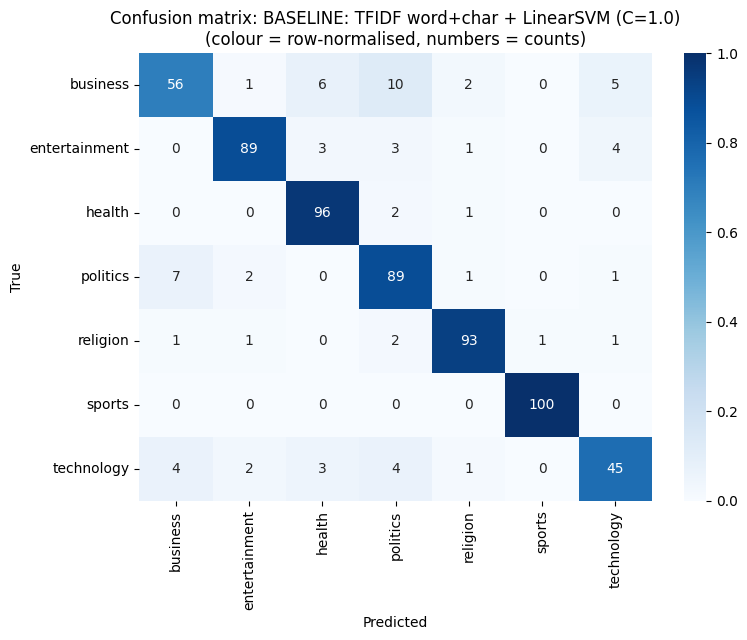

Misclassified: 69 / 637 -> saved baseline_errors.csv


In [5]:
if 'tune_df' in globals() and not tune_df.empty:

    svm_tunes = tune_df[tune_df["kind"] == "Word+char SVM"]
    best_C = float(svm_tunes.loc[svm_tunes["macro_f1"].idxmax(), "C"]) if not svm_tunes.empty else 1.0
else:
    best_C = 1.0

final_baseline = make_pipeline(make_union(word_tfidf(), char_tfidf()),
                               LinearSVC(C=best_C, random_state=SEED))
final_baseline.fit(X_train, y_train)

val_m  = compute_metrics(y_val,  final_baseline.predict(X_val))
test_pred = final_baseline.predict(X_test)
test_m = compute_metrics(y_test, test_pred)

name = f"BASELINE: TFIDF word+char + LinearSVM (C={best_C})"
log_result(name, val_m, test_m, notes="final baseline")
print("VAL :", {k: round(v, 3) for k, v in val_m.items()})
print("TEST:", {k: round(v, 3) for k, v in test_m.items()})

errors_baseline = full_report(name, y_test, test_pred, X_test, prefix="baseline")

         kind     C  accuracy  macro_precision  macro_recall  macro_f1  weighted_f1
       LogReg  10.0    0.9180           0.9125        0.9122    0.9115       0.9181
       LogReg  30.0    0.9148           0.9082        0.9092    0.9080       0.9152
       LogReg 100.0    0.9148           0.9082        0.9092    0.9080       0.9152
Word+char SVM   1.0    0.9085           0.9014        0.9022    0.9011       0.9089
       LogReg   3.0    0.9085           0.9028        0.9008    0.9008       0.9085
Word+char SVM  10.0    0.9022           0.8939        0.8957    0.8941       0.9026
Word+char SVM   3.0    0.9022           0.8939        0.8957    0.8941       0.9026
Word+char SVM   0.3    0.9022           0.8949        0.8944    0.8938       0.9026
Word+char SVM   0.1    0.8991           0.8924        0.8895    0.8899       0.8992
       LogReg   1.0    0.8959           0.8918        0.8852    0.8867       0.8952
VAL : {'accuracy': 0.918, 'macro_precision': 0.912, 'macro_recall': 0.912, '

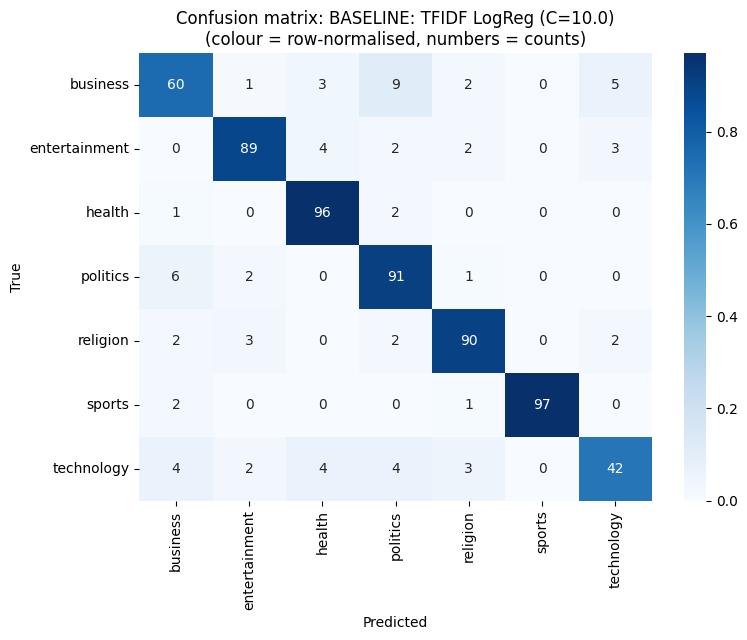

Misclassified: 72 / 637 -> saved baseline_errors.csv


In [6]:
import os, json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline, make_pipeline, make_union
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, classification_report, confusion_matrix)


if 'X_train' not in globals() or 'word_tfidf' not in globals() or 'log_result' not in globals():

    SEED = 42
    PROJECT_DIR = "/content/drive/MyDrive/hausa_news_project"
    if os.path.exists(PROJECT_DIR):
        os.chdir(PROJECT_DIR)
    else:
        from google.colab import drive
        drive.mount('/content/drive')
        os.makedirs(PROJECT_DIR, exist_ok=True)
        os.chdir(PROJECT_DIR)

    train = pd.read_csv("train.csv")
    val   = pd.read_csv("val.csv")
    test  = pd.read_csv("test.csv")
    meta  = json.load(open("labels.json"))
    id2label = {int(k): v for k, v in meta["id2label"].items()}
    label_names = [id2label[i] for i in range(len(id2label))]

    X_train, y_train = train["text_clean"], train["label_id"]
    X_val,   y_val   = val["text_clean"],   val["label_id"]
    X_test,  y_test  = test["text_clean"],  test["label_id"]

    from sklearn.feature_extraction.text import TfidfVectorizer
    word_tfidf = lambda: TfidfVectorizer(lowercase=True, ngram_range=(1, 2),
                                         min_df=2, sublinear_tf=True)
    char_tfidf = lambda: TfidfVectorizer(lowercase=True, analyzer="char_wb",
                                         ngram_range=(2, 5), min_df=2, sublinear_tf=True)

    RESULTS_FILE = "results.json"
    try:
        RESULTS = json.load(open(RESULTS_FILE))
    except FileNotFoundError:
        RESULTS = []

    def compute_metrics(y_true, y_pred):
        p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
        return {"accuracy": accuracy_score(y_true, y_pred),
                "macro_precision": p, "macro_recall": r, "macro_f1": f1,
                "weighted_f1": f1_score(y_true, y_pred, average="weighted")}

    def log_result(name, val_metrics, test_metrics=None, notes=""):
        row = {"model": name, "notes": notes,
               **{f"val_{k}": round(v, 4) for k, v in val_metrics.items()}}
        if test_metrics:
            row.update({f"test_{k}": round(v, 4) for k, v in test_metrics.items()})
        RESULTS[:] = [r for r in RESULTS if r["model"] != name]
        RESULTS.append(row)
        json.dump(RESULTS, open(RESULTS_FILE, "w"), indent=2)

    def full_report(name, y_true, y_pred, X_text, prefix="final"):
        print(f"\n===== {name} =====")
        print(classification_report(y_true, y_pred, target_names=label_names, digits=3))
        cm = confusion_matrix(y_true, y_pred)
        cm_norm = cm / cm.sum(axis=1, keepdims=True)
        plt.figure(figsize=(8, 6.5))
        sns.heatmap(cm_norm, annot=cm, fmt="d", cmap="Blues",
                    xticklabels=label_names, yticklabels=label_names)
        plt.xlabel("Predicted"); plt.ylabel("True")
        plt.title(f"Confusion matrix: {name}\n(colour = row-normalised, numbers = counts)")
        plt.tight_layout()
        plt.savefig(f"{prefix}_confusion_matrix.png", dpi=150)
        plt.show()
        err = pd.DataFrame({"text": X_text.values,
                            "true": [id2label[i] for i in y_true],
                            "pred": [id2label[i] for i in y_pred]})
        err = err[err["true"] != err["pred"]]
        err.to_csv(f"{prefix}_errors.csv", index=False)
        print(f"Misclassified: {len(err)} / {len(y_true)} -> saved {prefix}_errors.csv")
        return err

d = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
log_result("Majority class", compute_metrics(y_val, d.predict(X_val)), notes="trivial reference")

def make_pipe(kind, C):
    if kind == "LogReg":
        return make_pipeline(word_tfidf(), LogisticRegression(max_iter=3000, C=C, random_state=SEED))
    return make_pipeline(make_union(word_tfidf(), char_tfidf()), LinearSVC(C=C, random_state=SEED))

grid = [("LogReg", C) for C in [1, 3, 10, 30, 100]] + [("Word+char SVM", C) for C in [0.1, 0.3, 1, 3, 10]]
rows = []
for kind, C in grid:
    p = make_pipe(kind, C).fit(X_train, y_train)
    m = compute_metrics(y_val, p.predict(X_val))
    rows.append({"kind": kind, "C": C, **{k: round(v, 4) for k, v in m.items()}})
tune_df = pd.DataFrame(rows).sort_values("macro_f1", ascending=False)
print(tune_df.to_string(index=False)); tune_df.to_csv("baseline_tuning.csv", index=False)

best = tune_df.iloc[0]
final_baseline = make_pipe(best["kind"], float(best["C"])).fit(X_train, y_train)
val_m = compute_metrics(y_val, final_baseline.predict(X_val))
test_pred = final_baseline.predict(X_test); test_m = compute_metrics(y_test, test_pred)
name = f"BASELINE: TFIDF {best['kind']} (C={best['C']})"
log_result(name, val_m, test_m, notes="final baseline, chosen by val macro-F1")
print("VAL :", {k: round(v, 3) for k, v in val_m.items()})
print("TEST:", {k: round(v, 3) for k, v in test_m.items()})
errors_baseline = full_report(name, y_test, test_pred, X_test, prefix="baseline")

In [7]:
pd.set_option("display.max_colwidth", 160)
print(errors_baseline.groupby(["true", "pred"]).size().sort_values(ascending=False).head(10))
print(errors_baseline.sample(min(8, len(errors_baseline)), random_state=SEED)
      .assign(text=lambda d: d["text"].str[:160]))

pd.DataFrame(RESULTS)

true           pred      
business       politics      9
politics       business      6
business       technology    5
technology     politics      4
entertainment  health        4
technology     business      4
               health        4
entertainment  technology    3
business       health        3
technology     religion      3
dtype: int64
                                                                                                                                                                text  \
10   Johnson & Johnson: An ci tarar kamfanin biliyoyin naira. Wata kotu a Amurka ta ce tilas kamfanin hada magunguna na Johnson & Johnson ya biya tarar $572m sab...   
602  Me ya sa kwanaki hudu babu internet a Iran?. Kasashen duniya sun fara nuna damuwa kan daukewar internet a kasar Iran, a dai-dai lokacin da aka shiga kwanaki...   
66   Wasu 'yan Najeriya na caccakar ma'aikatan wutar lantarki kan yajin aiki. Wasu 'yan Najeriya, musamman masu amfani da shafukan sada zumunta, su

,model,notes,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_weighted_f1,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_weighted_f1
0,BiGRU + random init,"GRU, emb=random, dim=200, hidden=128, max_len=400",0.8423,0.8267,0.8266,0.8260,0.8423,NaN,NaN,NaN,NaN,NaN
1,BiLSTM + random init,"LSTM, emb=random, dim=200, hidden=128, max_len=400",0.8170,0.8063,0.7993,0.7995,0.8154,NaN,NaN,NaN,NaN,NaN
2,BiGRU + Word2Vec init,"GRU, emb=pretrained (trainable), dim=200, hidden=128, max_len=400",0.8927,0.8859,0.8888,0.8832,0.8955,NaN,NaN,NaN,NaN,NaN
3,BiLSTM + Word2Vec init,"LSTM, emb=pretrained (trainable), dim=200, hidden=128, max_len=400",0.9117,0.9063,0.9055,0.9035,0.9126,NaN,NaN,NaN,NaN,NaN
4,BiGRU + fastText init,"GRU, emb=pretrained (trainable), dim=200, hidden=128, max_len=400",0.8991,0.8944,0.8933,0.8897,0.8991,NaN,NaN,NaN,NaN,NaN
5,BiLSTM + fastText init,"LSTM, emb=pretrained (trainable), dim=200, hidden=128, max_len=400",0.8991,0.8912,0.8927,0.8902,0.8994,NaN,NaN,NaN,NaN,NaN
6,NEURAL: BiLSTM + Word2Vec init,"best neural model, test evaluated once",0.9117,0.9063,0.9055,0.9035,0.9126,0.8791,0.8751,0.8629,0.8640,0.8756
7,AfroXLMR-base | head256,"Davlan/afro-xlmr-base, len=256, trunc=head, lr=2e-05, bs=16x1, epochs=6",0.9180,0.9108,0.9161,0.9121,0.9183,NaN,NaN,NaN,NaN,NaN
8,AfriBERTa-base | head256,"castorini/afriberta_base, len=256, trunc=head, lr=5e-05, bs=16x1, epochs=4",0.9117,0.9037,0.9097,0.9049,0.9131,NaN,NaN,NaN,NaN,NaN
9,XLM-R-base | head256,"xlm-roberta-base, len=256, trunc=head, lr=2e-05, bs=16x1, epochs=6",0.8991,0.8888,0.8941,0.8901,0.8997,NaN,NaN,NaN,NaN,NaN


In [8]:
def hausa_norm(t):

    t = t.replace("’", "'").replace("‘", "'").replace("`", "'")
    return t.translate(str.maketrans({"ɓ": "b", "Ɓ": "B", "ɗ": "d", "Ɗ": "D",
                                      "ƙ": "k", "Ƙ": "K", "ƴ": "y", "Ƴ": "Y"}))

DEFAULT_TP   = r"(?u)\b\w\w+\b"
KEEP_APOS_TP = r"(?u)\b\w[\w']*\b"

rows = []
for norm in [False, True]:
    for tp_name, tp in [("default", DEFAULT_TP), ("keep-apostrophe", KEEP_APOS_TP)]:
        f = (lambda s: s.map(hausa_norm)) if norm else (lambda s: s)
        p = make_pipeline(
            TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, sublinear_tf=True, token_pattern=tp),
            LogisticRegression(max_iter=3000, C=10, random_state=SEED))
        p.fit(f(X_train), y_train)
        m = compute_metrics(y_val, p.predict(f(X_val)))
        log_result(f"PREPROC: LogReg norm={norm} tok={tp_name}", m, notes="Hausa orthography experiment")
        rows.append({"Normalised letters": norm, "Tokenizer": tp_name,
                     "Val accuracy": round(m["accuracy"], 3), "Val macro-F1": round(m["macro_f1"], 3)})

preproc_df = pd.DataFrame(rows)
print(preproc_df.to_string(index=False))
preproc_df.to_csv("preprocessing_experiment.csv", index=False)

 Normalised letters       Tokenizer  Val accuracy  Val macro-F1
              False         default         0.918         0.912
              False keep-apostrophe         0.912         0.906
               True         default         0.915         0.908
               True keep-apostrophe         0.905         0.899
